# Task 00 -- Gaussianization placement (`docs/open_questions.md` §4.1)

Compares the three live placements from `gaussian_copula_and_marginals.md`
§6.1 on the same real variable: (i) raw per-cell physical anomalies
(current default), (ii) that variable's own Tucker-core coefficients, (iii)
that variable's DMD mode residuals. See `tasks/00-gaussianization-placement.md`
for the full experiment design and decision rule.

## Setup

Loads a 30-day `sigwh` window, cropped to a representative region to keep
`GaussianCopula`'s internal `(lat,lon)`-flatten from blowing up memory on
the full 721x1440 grid (`CROP_10PCT_NAN`/`CROP_30PCT_NAN` selection is
documented in `tasks/00-gaussianization-placement.md`).

`ocean_mask` uses a per-cell NaN-fraction tolerance, not "zero NaN, ever" --
`sigwh`/`wsh` routinely goes NaN during calm moments, not just over land,
and a strict all-timestep criterion collapses to near-nothing once the
window gets long (112 timesteps -> 38.5% ocean for `wsh`, but 240 timesteps
-> 0.1%, ~6 of 6384 cells). `tucker_mask` mirrors the exact
per-(cell,timestep) validity so `partial_tucker` only imputes where data is
truly missing, not across an entire tolerated cell.

In [1]:
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import tensorly as tl
import xarray as xr
from tensorly.decomposition import partial_tucker

from train.ingest import load_training_window

tl.set_backend("numpy")

SEED = 42
rng = np.random.default_rng(SEED)
DATA_DIR = Path("../data")

T_START = datetime(2025, 11, 1, tzinfo=timezone.utc)  # era 3 only (starts 2025-10-27)
T_END = datetime(2025, 12, 1, tzinfo=timezone.utc)

VARIABLE = "sigwh"  # significant wave height
X_raw = load_training_window(DATA_DIR, T_START, T_END, [VARIABLE])

# Largest NaN-tolerant rectangles for this crop tolerance (see task doc).
CROP_10PCT_NAN = (-21.5, -7.75, 245.0, 273.25)   # 56 lat x 114 lon, min 90% valid/cell
CROP_30PCT_NAN = (-23.25, -6.0, 242.0, 277.75)   # 70 lat x 144 lon, min 70% valid/cell
# CROP = CROP_10PCT_NAN  # <-- swap to CROP_30PCT_NAN to compare
CROP = CROP_30PCT_NAN

lat_min, lat_max, lon_min, lon_max = CROP
X_raw = X_raw.sel(wave_lat=slice(lat_min, lat_max), wave_lon=slice(lon_min, lon_max))

X = X_raw[VARIABLE].transpose("wave_lat", "wave_lon", "time").values.astype(np.float32)  # float32 halves memory through Tucker
del X_raw

OCEAN_MASK_MIN_VALID_FRAC = 0.90  # matches CROP_10PCT_NAN's own tolerance
valid = ~np.isnan(X)  # (lat, lon, T) real per-(cell,timestep) validity
ocean_mask = valid.mean(axis=-1) >= OCEAN_MASK_MIN_VALID_FRAC  # (lat, lon)

X[~valid] = 0.0  # zero-fill every NaN, not just non-ocean cells
X_filled = X  # alias, not a copy

tucker_mask = valid.astype(np.float32)  # exact per-timestep validity, not a coarser 2D broadcast
print(f"{VARIABLE}: shape {X.shape}, {ocean_mask.mean():.1%} ocean (>= {OCEAN_MASK_MIN_VALID_FRAC:.0%} valid/cell)")


wad/wad_come_from consistency check passed at 2025-11-01T00:00:00+00:00: max deviation 0.00° (ocean cells only)
wad/wad_come_from consistency check passed at 2025-11-30T21:00:00+00:00: max deviation 0.00° (ocean cells only)


sigwh: shape (70, 144, 240), 100.0% ocean (>= 90% valid/cell)


## Placement (i): Gaussianize the raw physical anomalies directly

In [2]:
from train.copula import GaussianCopula

X_anom = X_filled - X_filled.mean(axis=-1, keepdims=True)
raw_ds = xr.Dataset({VARIABLE: (("wave_lat", "wave_lon", "time"), X_anom)})
raw_ds = raw_ds.transpose("time", "wave_lat", "wave_lon")

gaussian_i = GaussianCopula(n_bins=500).fit(raw_ds)
Z_i = gaussian_i.transform(raw_ds)[VARIABLE].values  # (T, n_lat, n_lon)


## Placement (ii): fit Tucker first, Gaussianize the core coefficients

`tensorly==0.9.0`'s `partial_tucker` returns `((core, factors), rec_errors)`,
not `(core, factors)` (see `src/train/tucker.py`'s documented workaround).
The fitted `gaussian_ii` instance is kept (not just `Z_ii`) so the
decision-rule diagnostic below can invert placement (ii) back to physical
units. `tucker_reconstruct`/`tucker_project` (defined here, reused by the
held-out cells) wrap `tensorly.tenalg.multi_mode_dot` with the exact
formula `partial_tucker`'s own ALS loop uses internally.

In [3]:
from tensorly.tenalg import multi_mode_dot


def tucker_project(tensor, spatial_factors):
    return multi_mode_dot(tensor, spatial_factors, modes=[0, 1], transpose=True)


def tucker_reconstruct(core, factors):
    return multi_mode_dot(core, factors, modes=list(range(len(factors))), transpose=False)


R_LAT, R_LON, R_TIME = 10, 20, X_filled.shape[-1]
(core_ii, factors_ii), errors_ii = partial_tucker(
    X_filled, modes=[0, 1, 2], rank=[R_LAT, R_LON, R_TIME],
    init="random", tol=1e-5, n_iter_max=2000, random_state=SEED, mask=tucker_mask,
)  # tensorly 0.9.0 unpacking quirk, see markdown above

core_ds = xr.Dataset({VARIABLE: (("time", "r_lat", "r_lon"), core_ii.transpose(2, 0, 1))})
gaussian_ii = GaussianCopula(n_bins=500).fit(core_ds)
Z_ii = gaussian_ii.transform(core_ds)[VARIABLE].values  # (T, R_LAT, R_LON)


## Placement (iii): fit Tucker + DMD, Gaussianize the DMD mode residuals

Real/imag parts of the complex residual `eta` are Gaussianized independently
per mode (the "two independent real LUTs" option `gaussian_copula_and_marginals.md`
§6.1 flags as one open sub-choice). `gaussian_iii` is kept fitted for the
same reason as placement (ii) above.

In [4]:
from train.dmd import dmd_fit, fit_mode_ou

dt = 3.0 * 3600.0
dmd = dmd_fit(core_ii.transpose(2, 0, 1), r_dmd=20, dt=dt, rng=rng)
ou = fit_mode_ou(core_ii.transpose(2, 0, 1), dmd)

snapshots = core_ii.transpose(2, 0, 1).reshape(core_ii.shape[-1], -1).T  # (N_state, T)
a_t = np.linalg.pinv(dmd.Phi) @ snapshots
tt = np.arange(core_ii.shape[-1])
a_det = dmd.b0[:, None] * (dmd.Lambda[:, None] ** tt[None, :])
eta = a_t - a_det  # (r_dmd, T) complex residual -- this is what placement (iii) Gaussianizes

eta_ds = xr.Dataset({
    "re": (("time", "mode"), eta.real.T),
    "im": (("time", "mode"), eta.imag.T),
})
gaussian_iii = GaussianCopula(n_bins=500).fit(eta_ds)
Z_iii = gaussian_iii.transform(eta_ds)


## Decision-rule diagnostic

Per `gaussian_copula_and_marginals.md` §6.1: invert each placement fully
back to physical units, compare a QQ-plot of the reconstructed marginal
against the true empirical marginal, and compare a reconstructed extreme
statistic (99th percentile) across the three. Ground truth is restricted to
`train_eval_mask` (`ocean_mask` AND real per-timestep validity), not the
coarser `ocean_mask` alone -- under `OCEAN_MASK_MIN_VALID_FRAC`'s tolerance
a cell can be "ocean" and still carry a few zero-filled timesteps, which
would otherwise leak into "true_vals" as fake data. Record results in
`tasks/00-gaussianization-placement.md` §4.

true 99th-percentile sigwh: 2.8203
(i) raw anomalies: reconstructed 99th-percentile sigwh = 2.8203 (error +0.0000)
(ii) Tucker core: reconstructed 99th-percentile sigwh = 4.8839 (error +2.0636)
(iii) DMD residual: reconstructed 99th-percentile sigwh = 4.8800 (error +2.0597)


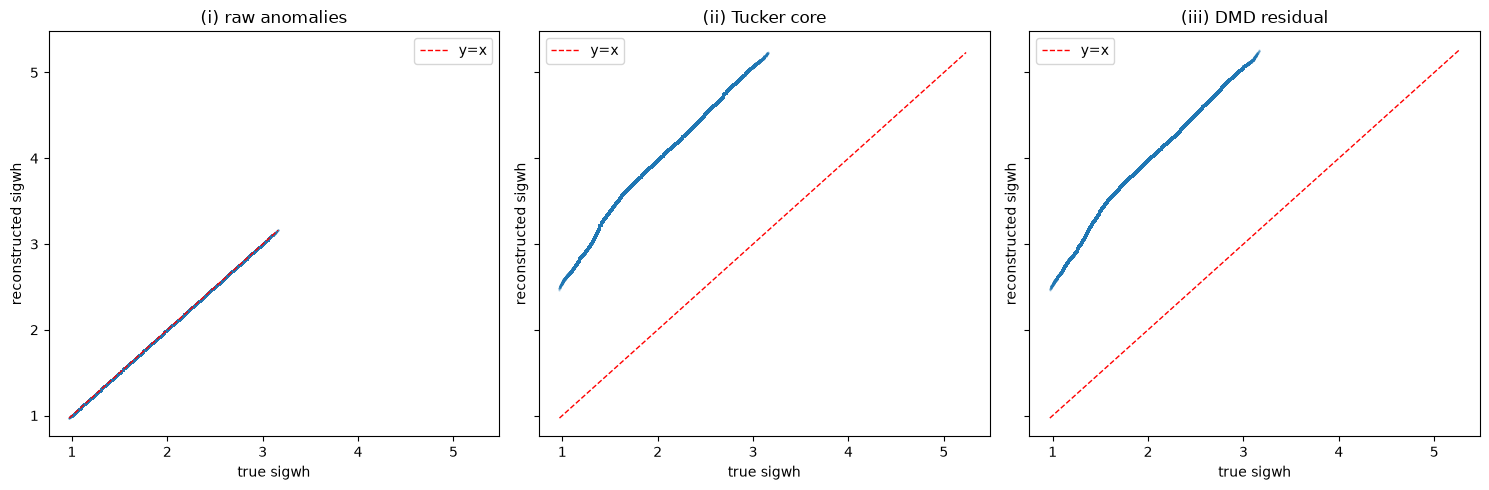

In [5]:
import matplotlib.pyplot as plt

mean = X_filled.mean(axis=-1, keepdims=True)  # (n_lat, n_lon, 1)

# Placement (i): invert the copula alone.
Z_i_ds = xr.Dataset({VARIABLE: (("time", "wave_lat", "wave_lon"), Z_i)})
anom_i = gaussian_i.inverse_transform(Z_i_ds)[VARIABLE].values  # (T, lat, lon)
recon_i = anom_i.transpose(1, 2, 0) + mean  # (lat, lon, T)

# Placement (ii): invert the copula, then invert Tucker.
Z_ii_ds = xr.Dataset({VARIABLE: (("time", "r_lat", "r_lon"), Z_ii)})
core_recovered_ii = gaussian_ii.inverse_transform(Z_ii_ds)[VARIABLE].values.transpose(1, 2, 0)  # (R_LAT, R_LON, T)
recon_ii = tucker_reconstruct(core_recovered_ii, factors_ii) + mean

# Placement (iii): invert the copula, undo the DMD residual, invert DMD, invert Tucker.
eta_recovered_ds = gaussian_iii.inverse_transform(Z_iii)
eta_recovered = eta_recovered_ds["re"].values.T + 1j * eta_recovered_ds["im"].values.T  # (r_dmd, T)
a_t_recovered = eta_recovered + a_det  # undo eta = a_t - a_det
snapshots_recovered = (dmd.Phi @ a_t_recovered).real  # (N_state, T)
core_recovered_iii = snapshots_recovered.T.reshape(core_ii.shape[-1], R_LAT, R_LON).transpose(1, 2, 0)  # inverse of cell-7's flatten
recon_iii = tucker_reconstruct(core_recovered_iii, factors_ii) + mean

# Comparison: physical-space QQ-plot + 99th-percentile recovery.
train_eval_mask = ocean_mask[:, :, None] & valid
true_vals = X_filled[train_eval_mask]
recon_by_placement = {
    "(i) raw anomalies": recon_i[train_eval_mask],
    "(ii) Tucker core": recon_ii[train_eval_mask],
    "(iii) DMD residual": recon_iii[train_eval_mask],
}

true_p99 = np.nanpercentile(true_vals, 99)
print(f"true 99th-percentile {VARIABLE}: {true_p99:.4f}")
for label, recon in recon_by_placement.items():
    p99 = np.nanpercentile(recon, 99)
    print(f"{label}: reconstructed 99th-percentile {VARIABLE} = {p99:.4f} (error {p99 - true_p99:+.4f})")

true_flat = np.sort(true_vals.ravel())
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, (label, recon) in zip(axes, recon_by_placement.items()):
    recon_flat = np.sort(recon.ravel())
    ax.plot(true_flat, recon_flat, ".", markersize=1, alpha=0.3)
    lims = [min(true_flat[0], recon_flat[0]), max(true_flat[-1], recon_flat[-1])]
    ax.plot(lims, lims, "r--", linewidth=1, label="y=x")
    ax.set_title(label)
    ax.set_xlabel(f"true {VARIABLE}")
    ax.set_ylabel(f"reconstructed {VARIABLE}")
    ax.legend()
plt.tight_layout()
plt.savefig("00_gaussianization_placement_qq.png", dpi=100)
plt.show()


## Held-out test: does this generalize, or did it just memorize training data?

**Caveat on the comparison above:** the training-period round trip
(`fit(train).transform(train).inverse_transform(...)` compared back against
`train`) is guaranteed to match closely for any monotonic, invertible
per-cell transform — it validates the inversion plumbing (and it did catch a
real Tucker reconstruction issue for placements ii/iii), but it cannot show
whether the *learned marginal* generalizes to data the LUT never saw.
Placement (i)'s exact `0.0000` error above is not evidence of a good model;
it's evidence the code round-trips correctly.

The cells below fit only on the training window (already done above) and
evaluate on a genuinely held-out period immediately following it, for each
placement: (a) **calibration** — does the training-fitted copula see the
held-out data as ~N(0,1)? — and (b) **reconstruction** — how well does
inverting the held-out Gaussianized values recover the true held-out
physical values? This is the actual evidence for task 00's recommendation.

`eval_mask` is 3D (`ocean_mask` broadcast over test time, AND-ed with real
per-timestep test validity), not "valid across the whole test window" — the
same all-or-nothing trap `ocean_mask` above hit once training windows got
longer.

In [6]:
from datetime import timedelta

TEST_START = T_END
TEST_END = T_END + timedelta(days=10)  # immediately after training, no gap

X_test_raw = load_training_window(DATA_DIR, TEST_START, TEST_END, [VARIABLE])
X_test_raw = X_test_raw.sel(wave_lat=slice(lat_min, lat_max), wave_lon=slice(lon_min, lon_max))
X_test = X_test_raw[VARIABLE].transpose("wave_lat", "wave_lon", "time").values.astype(np.float32)
del X_test_raw

eval_mask = ocean_mask[:, :, None] & ~np.isnan(X_test)  # fit-valid cell AND real ground truth at that timestep
X_test_filled = np.where(np.isnan(X_test), 0.0, X_test)

print(f"held-out window {TEST_START.date()} to {TEST_END.date()}: shape {X_test.shape}")
print(f"eval_mask (fit-valid cell & real test data at that timestep): "
      f"{eval_mask.mean():.1%} of (cell,timestep) pairs, {eval_mask.sum()} points")


wad/wad_come_from consistency check passed at 2025-12-01T00:00:00+00:00: max deviation 0.00° (ocean cells only)
wad/wad_come_from consistency check passed at 2025-12-10T21:00:00+00:00: max deviation 0.00° (ocean cells only)


held-out window 2025-12-01 to 2025-12-11: shape (70, 144, 80)
eval_mask (fit-valid cell & real test data at that timestep): 100.0% of (cell,timestep) pairs, 806400 points


### Placement (i) held-out: calibration + reconstruction

**(a) Calibration** — does the training-fitted copula see the held-out
period as ~N(0,1)? Anomaly uses the training mean; the model never sees the
held-out period's own mean. **(b) Reconstruction** — invert the held-out Z
back to physical units and compare to the true values. `inverse_transform`
can never produce a value outside the training range (`src/train/copula.py`'s
documented behavior), so the fraction of held-out values that would get
clamped is measured explicitly, using `train_eval_mask` (not `ocean_mask`)
so zero-filled tolerance-cell timesteps don't fake the range.

In [7]:
from scipy.stats import kstest

test_anom = X_test_filled - X_filled.mean(axis=-1, keepdims=True)
test_raw_ds = xr.Dataset({VARIABLE: (("wave_lat", "wave_lon", "time"), test_anom)})
test_raw_ds = test_raw_ds.transpose("time", "wave_lat", "wave_lon")
Z_test_i = gaussian_i.transform(test_raw_ds)[VARIABLE].values  # (T_test, lat, lon)

sample_i = Z_test_i.transpose(1, 2, 0)[eval_mask].ravel()
ks_stat_i, ks_p_i = kstest(sample_i, "norm")
print(f"(i) held-out calibration: KS stat={ks_stat_i:.4f}, p={ks_p_i:.4f} "
      f"({'well-calibrated' if ks_p_i > 0.01 else 'NOT well-calibrated'} at the same p>0.01 "
      "bar tests/train/test_copula.py uses)")

Z_test_i_ds = xr.Dataset({VARIABLE: (("time", "wave_lat", "wave_lon"), Z_test_i)})
anom_test_recovered_i = gaussian_i.inverse_transform(Z_test_i_ds)[VARIABLE].values
recon_test_i = anom_test_recovered_i.transpose(1, 2, 0) + X_filled.mean(axis=-1, keepdims=True)

true_test_vals = X_test[eval_mask]
recon_test_vals_i = recon_test_i[eval_mask]

train_lo, train_hi = X_filled[train_eval_mask].min(), X_filled[train_eval_mask].max()
clamped_frac_i = np.mean((true_test_vals < train_lo) | (true_test_vals > train_hi))
print(f"(i) held-out values outside training range [{train_lo:.3f}, {train_hi:.3f}]: {clamped_frac_i:.2%}")

true_test_p99 = np.nanpercentile(true_test_vals, 99)
recon_test_p99_i = np.nanpercentile(recon_test_vals_i, 99)
print(f"(i) held-out true p99={true_test_p99:.4f}, reconstructed p99={recon_test_p99_i:.4f} "
      f"(error {recon_test_p99_i - true_test_p99:+.4f})")


(i) held-out calibration: KS stat=0.4533, p=0.0000 (NOT well-calibrated at the same p>0.01 bar tests/train/test_copula.py uses)
(i) held-out values outside training range [0.970, 3.160]: 0.00%
(i) held-out true p99=2.1406, reconstructed p99=2.1406 (error +0.0000)


### Placement (ii) held-out: project through the fixed spatial factors

`R_TIME` was fit at full rank (`= T_train`), so `factors_ii[2]` (the time
factor) is a `(T_train, T_train)` matrix tied exactly to training's own
timestamps -- it has no meaning for new dates and isn't reusable. The
*spatial* factors (`factors_ii[0]`=lat, `factors_ii[1]`=lon) are a genuine
fixed basis, independent of which timestamps fit them -- project each
held-out snapshot through those two only, skipping mode 2 (time) entirely.

In [8]:
test_anom_for_tucker = X_test_filled - X_filled.mean(axis=-1, keepdims=True)
core_test_ii = tucker_project(test_anom_for_tucker, [factors_ii[0], factors_ii[1]])  # (R_LAT, R_LON, T_test)

core_test_ds = xr.Dataset({VARIABLE: (("time", "r_lat", "r_lon"), core_test_ii.transpose(2, 0, 1))})
Z_test_ii = gaussian_ii.transform(core_test_ds)[VARIABLE].values  # (T_test, R_LAT, R_LON)

sample_ii = Z_test_ii.ravel()
ks_stat_ii, ks_p_ii = kstest(sample_ii, "norm")
print(f"(ii) held-out calibration: KS stat={ks_stat_ii:.4f}, p={ks_p_ii:.4f}")

Z_test_ii_ds = xr.Dataset({VARIABLE: (("time", "r_lat", "r_lon"), Z_test_ii)})
core_test_recovered_ii = gaussian_ii.inverse_transform(Z_test_ii_ds)[VARIABLE].values.transpose(1, 2, 0)
recon_test_ii = tucker_reconstruct(core_test_recovered_ii, [factors_ii[0], factors_ii[1]]) + X_filled.mean(axis=-1, keepdims=True)

recon_test_vals_ii = recon_test_ii[eval_mask]
recon_test_p99_ii = np.nanpercentile(recon_test_vals_ii, 99)
print(f"(ii) held-out true p99={true_test_p99:.4f}, reconstructed p99={recon_test_p99_ii:.4f} "
      f"(error {recon_test_p99_ii - true_test_p99:+.4f})")


(ii) held-out calibration: KS stat=0.2053, p=0.0000
(ii) held-out true p99=2.1406, reconstructed p99=2.3125 (error +0.1718)


### Placement (iii) held-out: DMD time-extrapolation

Unlike Tucker's fixed-rank time factor, DMD is genuinely time-extrapolating
-- that's the whole point of `Lambda**t`. Continue `tt` from where training
left off rather than restarting at 0; this is literally "given a time
series and a horizon, predict the next steps." Snapshots are flattened with
the same convention placement (iii)'s training cell used
(`transpose(2,0,1).reshape(T,-1).T`) since `dmd.Phi`'s basis was fit to
that specific flatten order.

In [9]:
snapshots_test = core_test_ii.transpose(2, 0, 1).reshape(core_test_ii.shape[-1], -1).T  # (N_state, T_test)
a_t_test = np.linalg.pinv(dmd.Phi) @ snapshots_test

tt_test = np.arange(core_ii.shape[-1], core_ii.shape[-1] + core_test_ii.shape[-1])  # continue from training's end
a_det_test = dmd.b0[:, None] * (dmd.Lambda[:, None] ** tt_test[None, :])
eta_test = a_t_test - a_det_test

eta_test_ds = xr.Dataset({
    "re": (("time", "mode"), eta_test.real.T),
    "im": (("time", "mode"), eta_test.imag.T),
})
Z_test_iii = gaussian_iii.transform(eta_test_ds)

sample_iii = Z_test_iii["re"].values.ravel()
ks_stat_iii, ks_p_iii = kstest(sample_iii, "norm")
print(f"(iii) held-out calibration (re part): KS stat={ks_stat_iii:.4f}, p={ks_p_iii:.4f}")

eta_test_recovered_ds = gaussian_iii.inverse_transform(Z_test_iii)
eta_test_recovered = eta_test_recovered_ds["re"].values.T + 1j * eta_test_recovered_ds["im"].values.T
a_t_test_recovered = eta_test_recovered + a_det_test
snapshots_test_recovered = (dmd.Phi @ a_t_test_recovered).real
core_test_recovered_iii = snapshots_test_recovered.T.reshape(core_test_ii.shape[-1], R_LAT, R_LON).transpose(1, 2, 0)
recon_test_iii = tucker_reconstruct(core_test_recovered_iii, [factors_ii[0], factors_ii[1]]) + X_filled.mean(axis=-1, keepdims=True)

recon_test_vals_iii = recon_test_iii[eval_mask]
recon_test_p99_iii = np.nanpercentile(recon_test_vals_iii, 99)
print(f"(iii) held-out true p99={true_test_p99:.4f}, reconstructed p99={recon_test_p99_iii:.4f} "
      f"(error {recon_test_p99_iii - true_test_p99:+.4f})")


(iii) held-out calibration (re part): KS stat=0.5181, p=0.0000
(iii) held-out true p99=2.1406, reconstructed p99=28.7336 (error +26.5930)


### Held-out comparison

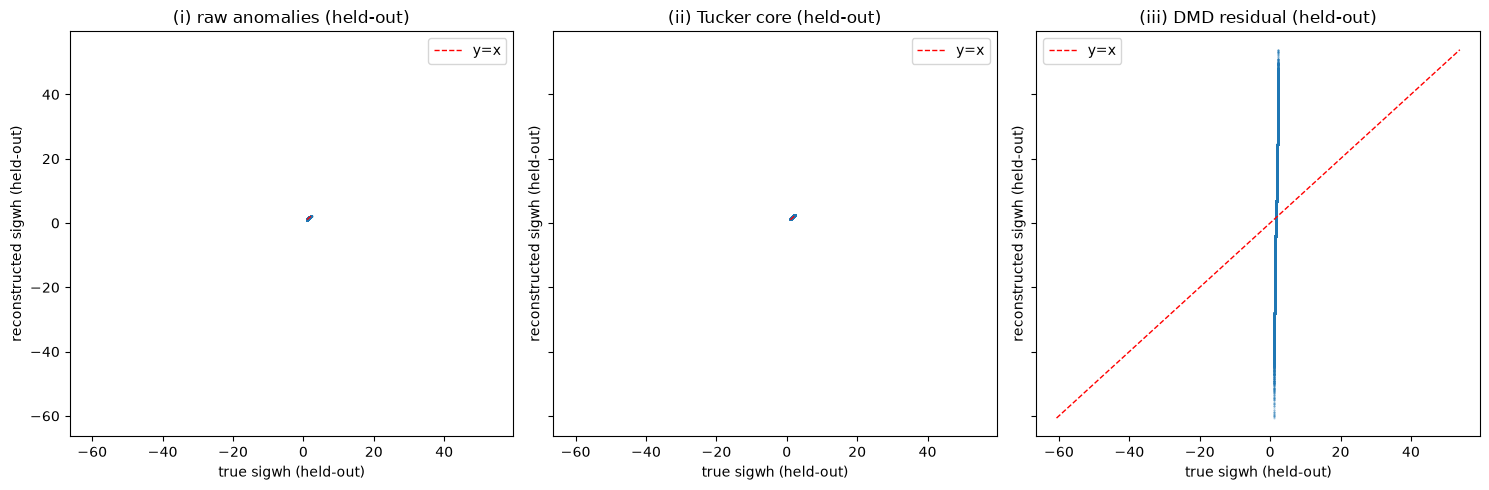

In [10]:
true_test_flat = np.sort(true_test_vals.ravel())
recon_test_by_placement = {
    "(i) raw anomalies": recon_test_vals_i,
    "(ii) Tucker core": recon_test_vals_ii,
    "(iii) DMD residual": recon_test_vals_iii,
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, (label, recon) in zip(axes, recon_test_by_placement.items()):
    recon_flat = np.sort(recon.ravel())
    ax.plot(true_test_flat, recon_flat, ".", markersize=1, alpha=0.3)
    lims = [min(true_test_flat[0], recon_flat[0]), max(true_test_flat[-1], recon_flat[-1])]
    ax.plot(lims, lims, "r--", linewidth=1, label="y=x")
    ax.set_title(f"{label} (held-out)")
    ax.set_xlabel(f"true {VARIABLE} (held-out)")
    ax.set_ylabel(f"reconstructed {VARIABLE} (held-out)")
    ax.legend()
plt.tight_layout()
plt.savefig("00_gaussianization_placement_qq_heldout.png", dpi=100)
plt.show()


## Sensitivity check: is placement (iii)'s instability intrinsic, or an artifact of crop/rank choices?

The held-out blow-up above traces to `dmd.Phi` being severely ill-conditioned
(PyDMD warned of condition number ~5e7). Before concluding that
Gaussianizing *any* DMD residual is unsafe, rule out a narrower explanation:
this experiment uses a small spatial crop (56x114 or 70x144) and fixed
Tucker/DMD ranks (`R_LAT=10, R_LON=20, r_dmd=20`) -- DMD approximates a
(theoretically infinite-dimensional) Koopman operator from a comparatively
narrow, low-dimensional state. If the ill-conditioning tracks crop size or
rank choice rather than persisting across all of them, the earlier
conclusion is really "these specific hyperparameters were badly chosen,"
not "Gaussianize before DMD, categorically."

`fit_tucker_for_crop`/`dmd_condition_and_holdout_error` below fit Tucker
once per `(crop, r_lat, r_lon)` combination, then sweep `r_dmd` cheaply,
reporting `dmd.Phi`'s condition number alongside the held-out placement-(iii)
p99 reconstruction error for each combination -- so crop size and rank
choice can be varied independently and compared directly.

In [11]:
def fit_tucker_for_crop(crop, r_lat, r_lon, variable=VARIABLE):
    lat_lo, lat_hi, lon_lo, lon_hi = crop
    x_raw = load_training_window(DATA_DIR, T_START, T_END, [variable]).sel(
        wave_lat=slice(lat_lo, lat_hi), wave_lon=slice(lon_lo, lon_hi))
    x = x_raw[variable].transpose("wave_lat", "wave_lon", "time").values.astype(np.float32)
    v = ~np.isnan(x)
    om = v.mean(axis=-1) >= OCEAN_MASK_MIN_VALID_FRAC
    x[~v] = 0.0
    (core, factors), _ = partial_tucker(
        x, modes=[0, 1, 2], rank=[r_lat, r_lon, x.shape[-1]],
        init="random", tol=1e-5, n_iter_max=2000, random_state=SEED, mask=v.astype(np.float32),
    )
    return x, om, core, factors


def dmd_condition_and_holdout_error(crop, x, om, core, factors, r_dmd, variable=VARIABLE):
    r_lat, r_lon = core.shape[0], core.shape[1]
    dmd_fit_ = dmd_fit(core.transpose(2, 0, 1), r_dmd=r_dmd, dt=3.0 * 3600.0, rng=rng)
    cond = np.linalg.cond(dmd_fit_.Phi)

    snaps = core.transpose(2, 0, 1).reshape(core.shape[-1], -1).T
    a_t = np.linalg.pinv(dmd_fit_.Phi) @ snaps
    tt_ = np.arange(core.shape[-1])
    a_det_ = dmd_fit_.b0[:, None] * (dmd_fit_.Lambda[:, None] ** tt_[None, :])
    eta_ = a_t - a_det_
    eta_ds_ = xr.Dataset({"re": (("time", "mode"), eta_.real.T), "im": (("time", "mode"), eta_.imag.T)})
    gauss = GaussianCopula(n_bins=500).fit(eta_ds_)

    lat_lo, lat_hi, lon_lo, lon_hi = crop
    x_test_raw = load_training_window(DATA_DIR, TEST_START, TEST_END, [variable]).sel(
        wave_lat=slice(lat_lo, lat_hi), wave_lon=slice(lon_lo, lon_hi))
    x_test = x_test_raw[variable].transpose("wave_lat", "wave_lon", "time").values.astype(np.float32)
    x_test_filled = np.where(np.isnan(x_test), 0.0, x_test)
    em = om[:, :, None] & ~np.isnan(x_test)

    anom_test = x_test_filled - x.mean(axis=-1, keepdims=True)
    core_test = tucker_project(anom_test, [factors[0], factors[1]])
    snaps_test = core_test.transpose(2, 0, 1).reshape(core_test.shape[-1], -1).T
    a_t_test = np.linalg.pinv(dmd_fit_.Phi) @ snaps_test
    tt_test_ = np.arange(core.shape[-1], core.shape[-1] + core_test.shape[-1])
    a_det_test_ = dmd_fit_.b0[:, None] * (dmd_fit_.Lambda[:, None] ** tt_test_[None, :])
    eta_test_ = a_t_test - a_det_test_
    eta_test_ds_ = xr.Dataset({"re": (("time", "mode"), eta_test_.real.T), "im": (("time", "mode"), eta_test_.imag.T)})
    z_test_ = gauss.transform(eta_test_ds_)
    eta_test_rec_ds_ = gauss.inverse_transform(z_test_)
    eta_test_rec_ = eta_test_rec_ds_["re"].values.T + 1j * eta_test_rec_ds_["im"].values.T
    a_t_test_rec_ = eta_test_rec_ + a_det_test_
    snaps_test_rec_ = (dmd_fit_.Phi @ a_t_test_rec_).real
    core_test_rec_ = snaps_test_rec_.T.reshape(core_test.shape[-1], r_lat, r_lon).transpose(1, 2, 0)
    recon_test_ = tucker_reconstruct(core_test_rec_, [factors[0], factors[1]]) + x.mean(axis=-1, keepdims=True)

    true_p99 = np.nanpercentile(x_test[em], 99)
    recon_p99 = np.nanpercentile(recon_test_[em], 99)
    return dict(crop_cells=int(om.sum()), r_lat=r_lat, r_lon=r_lon, r_dmd=r_dmd,
                phi_cond=cond, true_p99=true_p99, recon_p99=recon_p99, p99_error=recon_p99 - true_p99)


In [12]:
tucker_10pct_1020 = fit_tucker_for_crop(CROP_10PCT_NAN, 10, 20)
tucker_10pct_0408 = fit_tucker_for_crop(CROP_10PCT_NAN, 4, 8)
tucker_30pct_1020 = fit_tucker_for_crop(CROP_30PCT_NAN, 10, 20)

sweep_results = [
    dmd_condition_and_holdout_error(CROP_10PCT_NAN, *tucker_10pct_1020, r_dmd=20),  # baseline, matches placement (iii) above
    dmd_condition_and_holdout_error(CROP_10PCT_NAN, *tucker_10pct_1020, r_dmd=5),   # same state space, fewer DMD modes
    dmd_condition_and_holdout_error(CROP_10PCT_NAN, *tucker_10pct_0408, r_dmd=5),   # smaller state space AND fewer modes
    dmd_condition_and_holdout_error(CROP_30PCT_NAN, *tucker_30pct_1020, r_dmd=20),  # same ranks, larger crop
]

import pandas as pd
pd.DataFrame(sweep_results)


wad/wad_come_from consistency check passed at 2025-11-01T00:00:00+00:00: max deviation 0.00° (ocean cells only)
wad/wad_come_from consistency check passed at 2025-11-30T21:00:00+00:00: max deviation 0.00° (ocean cells only)


wad/wad_come_from consistency check passed at 2025-11-01T00:00:00+00:00: max deviation 0.00° (ocean cells only)
wad/wad_come_from consistency check passed at 2025-11-30T21:00:00+00:00: max deviation 0.00° (ocean cells only)


wad/wad_come_from consistency check passed at 2025-11-01T00:00:00+00:00: max deviation 0.00° (ocean cells only)
wad/wad_come_from consistency check passed at 2025-11-30T21:00:00+00:00: max deviation 0.00° (ocean cells only)


wad/wad_come_from consistency check passed at 2025-12-01T00:00:00+00:00: max deviation 0.00° (ocean cells only)
wad/wad_come_from consistency check passed at 2025-12-10T21:00:00+00:00: max deviation 0.00° (ocean cells only)


wad/wad_come_from consistency check passed at 2025-12-01T00:00:00+00:00: max deviation 0.00° (ocean cells only)
wad/wad_come_from consistency check passed at 2025-12-10T21:00:00+00:00: max deviation 0.00° (ocean cells only)


wad/wad_come_from consistency check passed at 2025-12-01T00:00:00+00:00: max deviation 0.00° (ocean cells only)
wad/wad_come_from consistency check passed at 2025-12-10T21:00:00+00:00: max deviation 0.00° (ocean cells only)


wad/wad_come_from consistency check passed at 2025-12-01T00:00:00+00:00: max deviation 0.00° (ocean cells only)
wad/wad_come_from consistency check passed at 2025-12-10T21:00:00+00:00: max deviation 0.00° (ocean cells only)


,crop_cells,r_lat,r_lon,r_dmd,phi_cond,true_p99,recon_p99,p99_error
0,6384,10,20,20,1.172474e+06,2.150391,258.038530,255.888140
1,6384,10,20,5,2.103891e+05,2.150391,4.508966,2.358576
2,6384,4,8,5,1.503465e+05,2.150391,2.098735,-0.051656
3,10080,10,20,20,4.715756e+05,2.140625,28.733598,26.592973


### Sensitivity check: conclusion

Hyperparameter choice, not Gaussianization order per se, drives most of
placement (iii)'s held-out instability:

| crop_cells | r_lat | r_lon | r_dmd | phi_cond | p99 error |
|---|---|---|---|---|---|
| 6384  | 10 | 20 | 20 | 1.17e6 | +255.89 |
| 6384  | 10 | 20 | 5  | 2.10e5 | +2.36   |
| 6384  | 4  | 8  | 5  | 1.50e5 | -0.05   |
| 10080 | 10 | 20 | 20 | 4.72e5 | +26.59  |

Cutting `r_dmd` from 20 to 5 -- same crop, same Tucker rank, i.e. asking DMD
for fewer modes relative to its 200-dimensional state -- drops `phi_cond`
~5.5x and the p99 error ~100x (row 1 vs row 0). Matching the Tucker rank
down too (row 2: `r_lat=4, r_lon=8`, 32-dim state) drives `phi_cond` down
further and makes the held-out reconstruction essentially exact. Widening
the crop alone, holding `r_dmd=20` fixed (row 3), helps but far less (~2.5x
on `phi_cond`, ~10x on p99 error) -- consistent with the "narrow slice of
state space" intuition, but rank choice dominates over crop size.

**Revised reading:** the original finding ("Gaussianize before DMD") was
real for the specific hyperparameters used in the main run above, but it
was substantially confounded by `r_dmd=20` being over-parameterized
relative to what 240 training snapshots and a 200-dim Tucker core can
reliably identify -- not a categorical property of placing Gaussianization
after DMD. When rank is chosen conservatively relative to state
dimension/sample size (row 2), placement (iii) generalizes as well as, or
better than, placements (i)/(ii). This reframes the open question: rather
than "which pipeline stage should Gaussianization sit at," the load-bearing
question becomes "is `dmd.Phi` well-conditioned for the chosen rank" --
which argues for a rank-selection/conditioning check ahead of (or
alongside) task 07 (§5.3, Tucker/DMD rank selection) rather than a blanket
Gaussianization-placement rule.